In [1]:
import pandas as pd
import numpy as np
from pathlib import Path

# Load the original dataset again
dataset_path = Path("../dataset/Disease_symptom_and_patient_profile_dataset.csv")

df_original = pd.read_csv(dataset_path)

# Create a working copy
df = df_original.copy()

print("Original dataset loaded successfully!")
print("Total records:", df_original.shape[0])
print("Total columns:", df_original.shape[1])

Original dataset loaded successfully!
Total records: 349
Total columns: 10


In [2]:
print("Dataset dimensions:", df.shape)

print("\nFirst 5 records:")
display(df.head())

print("\nLast 5 records:")
display(df.tail())

Dataset dimensions: (349, 10)

First 5 records:


,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
0,Influenza,Yes,No,Yes,Yes,19,Female,Low,Normal,Positive
1,Common Cold,No,Yes,Yes,No,25,Female,Normal,Normal,Negative
2,Eczema,No,Yes,Yes,No,25,Female,Normal,Normal,Negative
3,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive
4,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive



Last 5 records:


,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
344,Stroke,Yes,No,Yes,No,80,Female,High,High,Positive
345,Stroke,Yes,No,Yes,No,85,Male,High,High,Positive
346,Stroke,Yes,No,Yes,No,85,Male,High,High,Positive
347,Stroke,Yes,No,Yes,No,90,Female,High,High,Positive
348,Stroke,Yes,No,Yes,No,90,Female,High,High,Positive


In [3]:
# Display all column names
print("Column names:")
for i, col in enumerate(df.columns, start=1):
    print(f"{i}. {col}")

# Display data types and non-null counts
print("\nDataset information:")
df.info()

Column names:
1. Disease
2. Fever
3. Cough
4. Fatigue
5. Difficulty Breathing
6. Age
7. Gender
8. Blood Pressure
9. Cholesterol Level
10. Outcome Variable

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 349 entries, 0 to 348
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype 
---  ------                --------------  ----- 
 0   Disease               349 non-null    object
 1   Fever                 349 non-null    object
 2   Cough                 349 non-null    object
 3   Fatigue               349 non-null    object
 4   Difficulty Breathing  349 non-null    object
 5   Age                   349 non-null    int64 
 6   Gender                349 non-null    object
 7   Blood Pressure        349 non-null    object
 8   Cholesterol Level     349 non-null    object
 9   Outcome Variable      349 non-null    object
dtypes: int64(1), object(9)
memory usage: 27.4+ KB


In [4]:
for col in df.columns:
    print(f"\n{'='*45}")
    print("Column:", col)
    print("Data type:", df[col].dtype)
    print("Unique values:", df[col].nunique())
    print("Values:", df[col].unique())


Column: Disease
Data type: object
Unique values: 116
Values: ['Influenza' 'Common Cold' 'Eczema' 'Asthma' 'Hyperthyroidism'
 'Allergic Rhinitis' 'Anxiety Disorders' 'Diabetes' 'Gastroenteritis'
 'Pancreatitis' 'Rheumatoid Arthritis' 'Depression' 'Liver Cancer'
 'Stroke' 'Urinary Tract Infection' 'Dengue Fever' 'Hepatitis'
 'Kidney Cancer' 'Migraine' 'Muscular Dystrophy' 'Sinusitis'
 'Ulcerative Colitis' 'Bipolar Disorder' 'Bronchitis' 'Cerebral Palsy'
 'Colorectal Cancer' 'Hypertensive Heart Disease' 'Multiple Sclerosis'
 'Myocardial Infarction (Heart...' 'Urinary Tract Infection (UTI)'
 'Osteoporosis' 'Pneumonia' 'Atherosclerosis'
 'Chronic Obstructive Pulmonary...' 'Epilepsy' 'Hypertension'
 'Obsessive-Compulsive Disorde...' 'Psoriasis' 'Rubella' 'Cirrhosis'
 'Conjunctivitis (Pink Eye)' 'Liver Disease' 'Malaria' 'Spina Bifida'
 'Kidney Disease' 'Osteoarthritis' 'Klinefelter Syndrome' 'Acne'
 'Brain Tumor' 'Cystic Fibrosis' 'Glaucoma' 'Rabies' 'Chickenpox'
 'Coronary Artery Disease' 

In [5]:
# Count records for each disease
disease_counts = df["Disease"].value_counts()

print("Total unique diseases:", df["Disease"].nunique())

print("\nDisease frequency:")
display(disease_counts.to_frame(name="Record Count"))

print("\nDisease frequency summary:")
print(disease_counts.describe())

Total unique diseases: 116

Disease frequency:


,Record Count
Disease,
Asthma,23
Stroke,16
Osteoporosis,14
Hypertension,10
Diabetes,10
...,...
Autism Spectrum Disorder (ASD),1
Hypoglycemia,1
Fibromyalgia,1



Disease frequency summary:
count    116.000000
mean       3.008621
std        3.414791
min        1.000000
25%        1.000000
50%        1.000000
75%        5.000000
max       23.000000
Name: count, dtype: float64


In [6]:
# Check how many diseases have only 1, 2, 3, etc. records

print("Diseases with only 1 record:",
      (disease_counts == 1).sum())

print("Diseases with 2 records:",
      (disease_counts == 2).sum())

print("Diseases with 3 or more records:",
      (disease_counts >= 3).sum())

Diseases with only 1 record: 61
Diseases with 2 records: 18
Diseases with 3 or more records: 37


In [7]:
for col in df.columns:
    print(f"\n{'='*50}")
    print(f"Column: {col}")
    print(df[col].value_counts(dropna=False))
    


Column: Disease
Disease
Asthma                            23
Stroke                            16
Osteoporosis                      14
Hypertension                      10
Diabetes                          10
                                  ..
Autism Spectrum Disorder (ASD)     1
Hypoglycemia                       1
Fibromyalgia                       1
Eating Disorders (Anorexia,...     1
Williams Syndrome                  1
Name: count, Length: 116, dtype: int64

Column: Fever
Fever
Yes    175
No     174
Name: count, dtype: int64

Column: Cough
Cough
No     182
Yes    167
Name: count, dtype: int64

Column: Fatigue
Fatigue
Yes    242
No     107
Name: count, dtype: int64

Column: Difficulty Breathing
Difficulty Breathing
No     261
Yes     88
Name: count, dtype: int64

Column: Age
Age
45    42
35    42
50    34
40    31
55    30
60    30
30    28
65    23
42    16
70    16
38    14
29    11
25     7
31     4
48     3
52     3
28     3
85     2
80     2
90     2
57     1
56     1
43  

In [8]:
print("Age statistics:")
display(df["Age"].describe())

print("\nUnique age values:")
print(sorted(df["Age"].unique()))

Age statistics:


count    349.000000
mean      46.323782
std       13.085090
min       19.000000
25%       35.000000
50%       45.000000
75%       55.000000
max       90.000000
Name: Age, dtype: float64


Unique age values:
[19, 25, 28, 29, 30, 31, 32, 35, 38, 39, 40, 42, 43, 45, 48, 50, 52, 55, 56, 57, 60, 65, 70, 80, 85, 90]


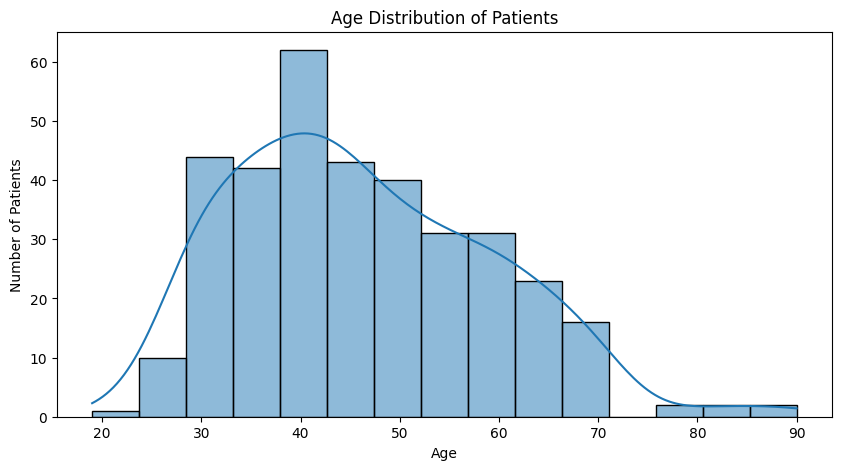

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=15,
    kde=True
)

plt.title("Age Distribution of Patients")
plt.xlabel("Age")
plt.ylabel("Number of Patients")

plt.show()

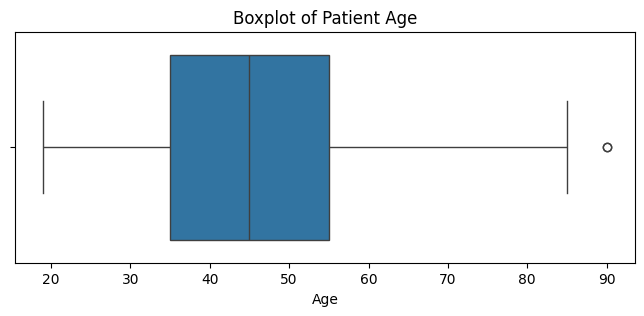

In [10]:
plt.figure(figsize=(8, 3))

sns.boxplot(x=df["Age"])

plt.title("Boxplot of Patient Age")
plt.xlabel("Age")

plt.show()

In [11]:
categorical_columns = df.select_dtypes(include="object").columns

for col in categorical_columns:
    print(f"\nColumn: {col}")
    print("Unique categories:", df[col].nunique())
    print(df[col].value_counts())
    


Column: Disease
Unique categories: 116
Disease
Asthma                            23
Stroke                            16
Osteoporosis                      14
Hypertension                      10
Diabetes                          10
                                  ..
Autism Spectrum Disorder (ASD)     1
Hypoglycemia                       1
Fibromyalgia                       1
Eating Disorders (Anorexia,...     1
Williams Syndrome                  1
Name: count, Length: 116, dtype: int64

Column: Fever
Unique categories: 2
Fever
Yes    175
No     174
Name: count, dtype: int64

Column: Cough
Unique categories: 2
Cough
No     182
Yes    167
Name: count, dtype: int64

Column: Fatigue
Unique categories: 2
Fatigue
Yes    242
No     107
Name: count, dtype: int64

Column: Difficulty Breathing
Unique categories: 2
Difficulty Breathing
No     261
Yes     88
Name: count, dtype: int64

Column: Gender
Unique categories: 2
Gender
Female    176
Male      173
Name: count, dtype: int64

Column: Blood

In [12]:
for col in df.select_dtypes(include="object").columns:

    print(f"\n{'='*45}")
    print("COLUMN:", col)

    summary = (
        df[col]
        .value_counts(dropna=False)
        .rename_axis("Category")
        .reset_index(name="Count")
    )

    print(summary.to_string(index=False))


COLUMN: Disease
                                    Category  Count
                                      Asthma     23
                                      Stroke     16
                                Osteoporosis     14
                                Hypertension     10
                                    Diabetes     10
                                    Migraine     10
                                   Influenza      8
                                   Pneumonia      8
                                  Bronchitis      8
                             Hyperthyroidism      7
                              Hypothyroidism      7
                              Osteoarthritis      6
                               Kidney Cancer      6
                                 Common Cold      6
                                Liver Cancer      6
                                  Depression      6
                        Rheumatoid Arthritis      6
                                      Eczema   

In [13]:
columns_to_check = [
    "Fever",
    "Cough",
    "Fatigue",
    "Difficulty Breathing",
    "Gender",
    "Blood Pressure",
    "Cholesterol Level"
]

for col in columns_to_check:
    print(f"\n{col}")
    print(df[col].value_counts(dropna=False).to_dict())
    


Fever
{'Yes': 175, 'No': 174}

Cough
{'No': 182, 'Yes': 167}

Fatigue
{'Yes': 242, 'No': 107}

Difficulty Breathing
{'No': 261, 'Yes': 88}

Gender
{'Female': 176, 'Male': 173}

Blood Pressure
{'High': 167, 'Normal': 164, 'Low': 18}

Cholesterol Level
{'High': 166, 'Normal': 149, 'Low': 34}


In [14]:
# Missing values in original dataset
print("Missing values:")
print(df.isnull().sum())

# Exact duplicate rows
print("\nExact duplicate rows:", df.duplicated().sum())

# Number of rows involved in duplicate groups
duplicate_rows = df[df.duplicated(keep=False)]

print("Rows belonging to duplicate groups:", len(duplicate_rows))

Missing values:
Disease                 0
Fever                   0
Cough                   0
Fatigue                 0
Difficulty Breathing    0
Age                     0
Gender                  0
Blood Pressure          0
Cholesterol Level       0
Outcome Variable        0
dtype: int64

Exact duplicate rows: 49
Rows belonging to duplicate groups: 98


In [15]:
duplicate_rows = df[df.duplicated(keep=False)]

display(
    duplicate_rows.sort_values(
        by=list(df.columns)
    ).head(20)
)

,Disease,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Outcome Variable
311,Alzheimer's Disease,No,Yes,No,No,65,Male,Normal,High,Positive
312,Alzheimer's Disease,No,Yes,No,No,65,Male,Normal,High,Positive
327,Alzheimer's Disease,Yes,No,Yes,No,70,Female,High,Normal,Negative
328,Alzheimer's Disease,Yes,No,Yes,No,70,Female,High,Normal,Negative
58,Asthma,No,Yes,Yes,Yes,35,Female,High,Normal,Negative
59,Asthma,No,Yes,Yes,Yes,35,Female,High,Normal,Negative
125,Asthma,Yes,No,Yes,Yes,40,Male,Normal,High,Positive
126,Asthma,Yes,No,Yes,Yes,40,Male,Normal,High,Positive
3,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive
4,Asthma,Yes,Yes,No,Yes,25,Male,Normal,Normal,Positive


In [16]:
# Count extra duplicate occurrences by disease
duplicate_counts = (
    df[df.duplicated(keep="first")]
    ["Disease"]
    .value_counts()
)

print("Extra duplicate records by disease:")
display(duplicate_counts.to_frame(name="Duplicate Count"))

print("\nTotal extra duplicate records:",
      duplicate_counts.sum())

print("\nDiseases affected:",
      duplicate_counts.size)

Extra duplicate records by disease:


,Duplicate Count
Disease,
Asthma,7
Stroke,5
Hypothyroidism,2
Chronic Obstructive Pulmonary Disease (COPD),2
Alzheimer's Disease,2
Osteoporosis,2
Coronary Artery Disease,2
Parkinson's Disease,2
Multiple Sclerosis,2



Total extra duplicate records: 49

Diseases affected: 31


In [17]:
# Features excluding the target and outcome
feature_columns = [
    "Fever",
    "Cough",
    "Fatigue",
    "Difficulty Breathing",
    "Age",
    "Gender",
    "Blood Pressure",
    "Cholesterol Level"
]

# Find identical patient profiles
profile_groups = (
    df.groupby(feature_columns)["Disease"]
    .agg(["count", "nunique", list])
    .reset_index()
)

# Profiles associated with multiple diseases
conflicting_profiles = profile_groups[
    profile_groups["nunique"] > 1
]

print("Total unique patient profiles:", len(profile_groups))

print("Profiles associated with multiple diseases:",
      len(conflicting_profiles))

display(conflicting_profiles.head(15))

Total unique patient profiles: 244
Profiles associated with multiple diseases: 45


,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,count,nunique,list
7,No,No,No,No,45,Female,Low,Normal,2,2,"[Migraine, Urinary Tract Infection]"
13,No,No,Yes,No,30,Female,High,High,3,3,"[Bipolar Disorder, Hypertensive Heart Disease,..."
18,No,No,Yes,No,35,Female,Normal,High,2,2,"[Cirrhosis, Depression]"
19,No,No,Yes,No,35,Female,Normal,Low,2,2,"[Allergic Rhinitis, Rheumatoid Arthritis]"
21,No,No,Yes,No,35,Male,High,High,4,4,"[Epilepsy, Kidney Cancer, Liver Disease, Ulcer..."
23,No,No,Yes,No,35,Male,Normal,Normal,2,2,"[Atherosclerosis, Obsessive-Compulsive Disorde..."
26,No,No,Yes,No,40,Female,High,High,4,4,"[Coronary Artery Disease, Eating Disorders (An..."
29,No,No,Yes,No,40,Male,High,Normal,2,2,"[Glaucoma, Osteoarthritis]"
30,No,No,Yes,No,40,Male,Normal,Normal,2,2,"[Acne, Brain Tumor]"
32,No,No,Yes,No,45,Female,High,High,3,3,"[Crohn's Disease, Depression, Hypothyroidism]"


In [18]:
conflicting_rows = conflicting_profiles["count"].sum()

print("Total records:", len(df))
print("Unique patient profiles:", len(profile_groups))
print("Conflicting profiles:", len(conflicting_profiles))
print("Records belonging to conflicting profiles:", conflicting_rows)
print(
    "Percentage of records with conflicting profiles:",
    round((conflicting_rows / len(df)) * 100, 2), "%"
)

Total records: 349
Unique patient profiles: 244
Conflicting profiles: 45
Records belonging to conflicting profiles: 105
Percentage of records with conflicting profiles: 30.09 %


In [19]:
# Check how Outcome Variable is distributed across diseases
disease_outcome = (
    df.groupby("Disease")["Outcome Variable"]
    .agg(["count", "nunique", list])
    .reset_index()
)

# Diseases having both Positive and Negative outcomes
mixed_outcomes = disease_outcome[
    disease_outcome["nunique"] > 1
]

print("Total disease categories:", df["Disease"].nunique())

print("Diseases with only one outcome:",
      (disease_outcome["nunique"] == 1).sum())

print("Diseases with both outcomes:",
      len(mixed_outcomes))

display(disease_outcome.head(20))

Total disease categories: 116
Diseases with only one outcome: 81
Diseases with both outcomes: 35


,Disease,count,nunique,list
0,Acne,1,1,[Negative]
1,Allergic Rhinitis,6,2,"[Negative, Negative, Negative, Negative, Posit..."
2,Alzheimer's Disease,5,2,"[Positive, Positive, Positive, Negative, Negat..."
3,Anemia,1,1,[Negative]
4,Anxiety Disorders,6,2,"[Negative, Positive, Negative, Positive, Negat..."
5,Appendicitis,1,1,[Negative]
6,Asthma,23,2,"[Positive, Positive, Positive, Positive, Posit..."
7,Atherosclerosis,1,1,[Negative]
8,Autism Spectrum Disorder (ASD),1,1,[Negative]
9,Bipolar Disorder,1,1,[Positive]


In [20]:
print("Outcome Variable distribution:")
display(df["Outcome Variable"].value_counts())

print("\nOutcome percentage:")
display(
    df["Outcome Variable"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

Outcome Variable distribution:


Outcome Variable
Positive    186
Negative    163
Name: count, dtype: int64


Outcome percentage:


Outcome Variable
Positive    53.3
Negative    46.7
Name: proportion, dtype: float64

In [21]:
# Create a separate working copy
feature_columns = [
    "Fever",
    "Cough",
    "Fatigue",
    "Difficulty Breathing",
    "Age",
    "Gender",
    "Blood Pressure",
    "Cholesterol Level"
]

target_column = "Disease"

model_df = df[feature_columns + [target_column]].copy()

print("Original dataset shape:", df.shape)
print("Working dataset shape:", model_df.shape)

display(model_df.head())

Original dataset shape: (349, 10)
Working dataset shape: (349, 9)


,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Disease
0,Yes,No,Yes,Yes,19,Female,Low,Normal,Influenza
1,No,Yes,Yes,No,25,Female,Normal,Normal,Common Cold
2,No,Yes,Yes,No,25,Female,Normal,Normal,Eczema
3,Yes,Yes,No,Yes,25,Male,Normal,Normal,Asthma
4,Yes,Yes,No,Yes,25,Male,Normal,Normal,Asthma


In [22]:
print("Missing values in working dataset:")
display(model_df.isnull().sum())

print("\nExact duplicate rows in working dataset:")
print(model_df.duplicated().sum())

print("\nNumber of unique diseases:")
print(model_df["Disease"].nunique())

print("\nData types:")
display(model_df.dtypes)

Missing values in working dataset:


Fever                   0
Cough                   0
Fatigue                 0
Difficulty Breathing    0
Age                     0
Gender                  0
Blood Pressure          0
Cholesterol Level       0
Disease                 0
dtype: int64


Exact duplicate rows in working dataset:
49

Number of unique diseases:
116

Data types:


Fever                   object
Cough                   object
Fatigue                 object
Difficulty Breathing    object
Age                      int64
Gender                  object
Blood Pressure          object
Cholesterol Level       object
Disease                 object
dtype: object

In [23]:
# Count duplicate rows for each disease
duplicate_counts = (
    model_df[model_df.duplicated(keep="first")]
    ["Disease"]
    .value_counts()
)

print("Number of diseases affected by duplicates:",
      len(duplicate_counts))

print("\nDuplicate counts by disease:")
display(duplicate_counts)

Number of diseases affected by duplicates: 31

Duplicate counts by disease:


Disease
Asthma                                          7
Stroke                                          5
Hypothyroidism                                  2
Chronic Obstructive Pulmonary Disease (COPD)    2
Alzheimer's Disease                             2
Osteoporosis                                    2
Coronary Artery Disease                         2
Parkinson's Disease                             2
Multiple Sclerosis                              2
Hyperthyroidism                                 2
Chickenpox                                      1
Tuberculosis                                    1
Dengue Fever                                    1
Bronchitis                                      1
Hepatitis B                                     1
Measles                                         1
Typhoid Fever                                   1
Pneumonia                                       1
Rubella                                         1
Malaria                                   

In [24]:
categorical_columns = [
    "Fever",
    "Cough",
    "Fatigue",
    "Difficulty Breathing",
    "Gender",
    "Blood Pressure",
    "Cholesterol Level"
]

for column in categorical_columns:
    print(f"\n{column}:")
    print(model_df[column].unique())


Fever:
['Yes' 'No']

Cough:
['No' 'Yes']

Fatigue:
['Yes' 'No']

Difficulty Breathing:
['Yes' 'No']

Gender:
['Female' 'Male']

Blood Pressure:
['Low' 'Normal' 'High']

Cholesterol Level:
['Normal' 'Low' 'High']


In [25]:
for column in categorical_columns:
    has_spaces = model_df[column].ne(model_df[column].str.strip()).sum()
    print(f"{column}: {has_spaces} values with extra spaces")

Fever: 0 values with extra spaces
Cough: 0 values with extra spaces
Fatigue: 0 values with extra spaces
Difficulty Breathing: 0 values with extra spaces
Gender: 0 values with extra spaces
Blood Pressure: 0 values with extra spaces
Cholesterol Level: 0 values with extra spaces


In [26]:
# Create a separate copy for preprocessing
encoded_df = model_df.copy()

# Binary encoding
binary_mapping = {
    "Yes": 1,
    "No": 0
}

for column in [
    "Fever",
    "Cough",
    "Fatigue",
    "Difficulty Breathing"
]:
    encoded_df[column] = encoded_df[column].map(binary_mapping)

encoded_df["Gender"] = encoded_df["Gender"].map({
    "Female": 0,
    "Male": 1
})

print("Binary encoding completed.")
display(encoded_df.head())

Binary encoding completed.


,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Blood Pressure,Cholesterol Level,Disease
0,1,0,1,1,19,0,Low,Normal,Influenza
1,0,1,1,0,25,0,Normal,Normal,Common Cold
2,0,1,1,0,25,0,Normal,Normal,Eczema
3,1,1,0,1,25,1,Normal,Normal,Asthma
4,1,1,0,1,25,1,Normal,Normal,Asthma


In [27]:
# One-hot encode Blood Pressure and Cholesterol Level
encoded_df = pd.get_dummies(
    encoded_df,
    columns=["Blood Pressure", "Cholesterol Level"],
    dtype=int
)

print("One-hot encoding completed.")
print("Encoded dataset shape:", encoded_df.shape)

display(encoded_df.head())

One-hot encoding completed.
Encoded dataset shape: (349, 13)


,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Disease,Blood Pressure_High,Blood Pressure_Low,Blood Pressure_Normal,Cholesterol Level_High,Cholesterol Level_Low,Cholesterol Level_Normal
0,1,0,1,1,19,0,Influenza,0,1,0,0,0,1
1,0,1,1,0,25,0,Common Cold,0,0,1,0,0,1
2,0,1,1,0,25,0,Eczema,0,0,1,0,0,1
3,1,1,0,1,25,1,Asthma,0,0,1,0,0,1
4,1,1,0,1,25,1,Asthma,0,0,1,0,0,1


In [28]:
print("Dataset shape:", encoded_df.shape)

print("\nData types:")
display(encoded_df.dtypes)

print("\nMissing values:")
display(encoded_df.isnull().sum())

print("\nEncoded feature columns:")
print(encoded_df.columns.tolist())


Dataset shape: (349, 13)

Data types:


Fever                        int64
Cough                        int64
Fatigue                      int64
Difficulty Breathing         int64
Age                          int64
Gender                       int64
Disease                     object
Blood Pressure_High          int32
Blood Pressure_Low           int32
Blood Pressure_Normal        int32
Cholesterol Level_High       int32
Cholesterol Level_Low        int32
Cholesterol Level_Normal     int32
dtype: object


Missing values:


Fever                       0
Cough                       0
Fatigue                     0
Difficulty Breathing        0
Age                         0
Gender                      0
Disease                     0
Blood Pressure_High         0
Blood Pressure_Low          0
Blood Pressure_Normal       0
Cholesterol Level_High      0
Cholesterol Level_Low       0
Cholesterol Level_Normal    0
dtype: int64


Encoded feature columns:
['Fever', 'Cough', 'Fatigue', 'Difficulty Breathing', 'Age', 'Gender', 'Disease', 'Blood Pressure_High', 'Blood Pressure_Low', 'Blood Pressure_Normal', 'Cholesterol Level_High', 'Cholesterol Level_Low', 'Cholesterol Level_Normal']


In [29]:
# Count records available for each disease
disease_counts = encoded_df["Disease"].value_counts()

# Summarize how many disease categories have each level of representation
class_summary = {
    "Diseases with 1 record": (disease_counts == 1).sum(),
    "Diseases with 2 records": (disease_counts == 2).sum(),
    "Diseases with 3-5 records": (
        (disease_counts >= 3) & (disease_counts <= 5)
    ).sum(),
    "Diseases with more than 5 records": (disease_counts > 5).sum()
}

display(pd.Series(class_summary, name="Number of disease categories"))

print("\nDisease categories with the fewest records:")
display(disease_counts.sort_values().head(20))

Diseases with 1 record               61
Diseases with 2 records              18
Diseases with 3-5 records            16
Diseases with more than 5 records    21
Name: Number of disease categories, dtype: int64


Disease categories with the fewest records:


Disease
Hemorrhoids                         1
Conjunctivitis (Pink Eye)           1
Spina Bifida                        1
Atherosclerosis                     1
Down Syndrome                       1
Lymphoma                            1
Otitis Media (Ear Infection)        1
Thyroid Cancer                      1
Bladder Cancer                      1
Polio                               1
Osteomyelitis                       1
Tourette Syndrome                   1
Dementia                            1
Diverticulitis                      1
Breast Cancer                       1
Chronic Kidney Disease              1
Systemic Lupus Erythematosus...     1
Polycystic Ovary Syndrome (PCOS)    1
Cholecystitis                       1
Schizophrenia                       1
Name: count, dtype: int64

In [30]:
# Check how many diseases have enough records
for minimum in [2, 3, 5, 10]:
    eligible = (disease_counts >= minimum).sum()

    print(
        f"Diseases with at least {minimum} records: "
        f"{eligible}"
    )

Diseases with at least 2 records: 55
Diseases with at least 3 records: 37
Diseases with at least 5 records: 32
Diseases with at least 10 records: 6


In [31]:
from pathlib import Path

output_path = Path("../dataset/processed")
output_path.mkdir(parents=True, exist_ok=True)

encoded_df.to_csv(
    output_path / "encoded_disease_dataset.csv",
    index=False
)

print("Encoded dataset saved successfully!")
print("Location:", output_path / "encoded_disease_dataset.csv")

Encoded dataset saved successfully!
Location: ..\dataset\processed\encoded_disease_dataset.csv


In [32]:
saved_df = pd.read_csv(
    "../dataset/processed/encoded_disease_dataset.csv"
)

print("Saved dataset shape:", saved_df.shape)
print("Missing values:", saved_df.isnull().sum().sum())
print("Disease categories:", saved_df["Disease"].nunique())

display(saved_df.head())

Saved dataset shape: (349, 13)
Missing values: 0
Disease categories: 116


,Fever,Cough,Fatigue,Difficulty Breathing,Age,Gender,Disease,Blood Pressure_High,Blood Pressure_Low,Blood Pressure_Normal,Cholesterol Level_High,Cholesterol Level_Low,Cholesterol Level_Normal
0,1,0,1,1,19,0,Influenza,0,1,0,0,0,1
1,0,1,1,0,25,0,Common Cold,0,0,1,0,0,1
2,0,1,1,0,25,0,Eczema,0,0,1,0,0,1
3,1,1,0,1,25,1,Asthma,0,0,1,0,0,1
4,1,1,0,1,25,1,Asthma,0,0,1,0,0,1


In [33]:
from sklearn.model_selection import GroupShuffleSplit

X = saved_df.drop(columns=["Disease"])
y = saved_df["Disease"]

# Group identical patient profiles together
groups = X.astype(str).agg("|".join, axis=1)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Unique patient-profile groups:", groups.nunique())

Feature shape: (349, 12)
Target shape: (349,)
Unique patient-profile groups: 244


In [34]:
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, test_idx = next(
    gss.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Training diseases:", y_train.nunique())
print("Testing diseases:", y_test.nunique())

Training records: 284
Testing records: 65
Training diseases: 110
Testing diseases: 34


In [35]:
train_diseases = set(y_train.unique())
test_diseases = set(y_test.unique())

common_diseases = train_diseases & test_diseases
unseen_test_diseases = test_diseases - train_diseases
missing_test_diseases = train_diseases - test_diseases

print("Diseases present in both sets:", len(common_diseases))
print("Diseases only in testing:", len(unseen_test_diseases))
print("Diseases only in training:", len(missing_test_diseases))

print("\nUnseen test diseases:")
print(sorted(unseen_test_diseases))

Diseases present in both sets: 28
Diseases only in testing: 6
Diseases only in training: 82

Unseen test diseases:
['Cataracts', 'Cirrhosis', 'Hemorrhoids', 'Lymphoma', 'Muscular Dystrophy', 'Testicular Cancer']


In [36]:
from pathlib import Path

split_path = Path("../dataset/splits")
split_path.mkdir(parents=True, exist_ok=True)

# Combine features and target
train_df = X_train.copy()
train_df["Disease"] = y_train

test_df = X_test.copy()
test_df["Disease"] = y_test

# Save both files
train_df.to_csv(split_path / "train.csv", index=False)
test_df.to_csv(split_path / "test.csv", index=False)

print("Shared split saved successfully!")
print("Training file:", split_path / "train.csv")
print("Testing file:", split_path / "test.csv")

Shared split saved successfully!
Training file: ..\dataset\splits\train.csv
Testing file: ..\dataset\splits\test.csv
